# Blink preprocessing

One important step in the processing of pupillometric data is the handling of blinks. In `pypillometry`, this is done in three steps:

1. detect blinks (`pupil_blinks_detect()`)
2. merge blinks that are very close to each other (`blinks_merge_close()`)
3. interpolate the pupil signal during blinks (`pupil_blinks_interpolate()`)

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt

## Blink detection

The first step is the identification of blinks. For this, we can use the `pupil_blinks_detect()` function. With `apply_mask=True`, the detected blinks are stored in the object and the pupil data during blinks is masked:

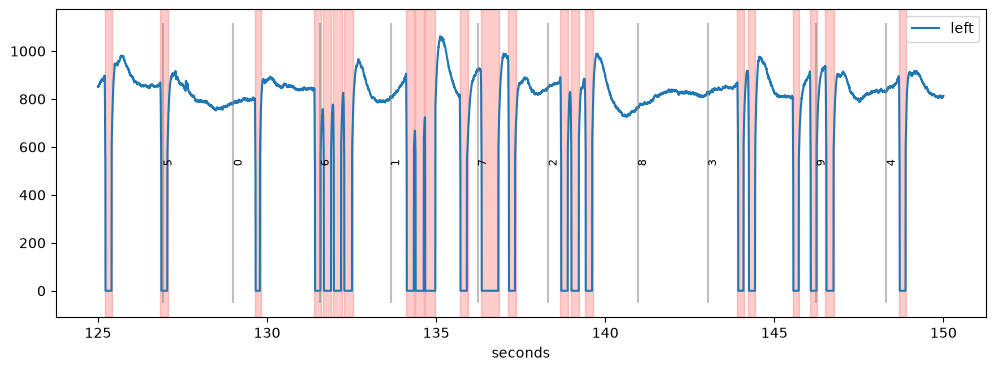

In [2]:
d = pp.PupilData.from_file("../../data/example_shortblinks.pd")
d.pupil_blinks_detect(apply_mask=True)

plt.figure(figsize=(12, 4))
d.plot.pupil_plot()

Detected blinks are marked in red in the plot. In this case, the blink detection did a reasonable job with the default settings, but `pupil_blinks_detect()` has many parameters that can be tweaked.

The function looks for blinks using two strategies (argument `strategies`):

- `"zero"`: blinks are runs of missing data, i.e., `NaN` or another placeholder value for missing data (argument `blink_val`, default `0`)
- `"velocity"`: blinks are everything between a fast drop and a fast rise of the pupil signal, based on its velocity profile

The blinks found with both strategies are merged, and only blinks that are at least `min_duration` long are kept.

As a consequence, there are several parameters that can be adjusted (see the [API docs](../api/index.rst) for details).
The most important ones are the following (durations are in ms or can be given with units, e.g., `20 * u.ms` or `"20 ms"`):

- `min_duration`: minimum duration for a blink
- `vel_onset`: negative velocity (in pupil units per ms) that needs to be crossed at the blink onset; can also be given as a percentile of the velocity distribution (e.g., `"5%"`)
- `vel_offset`: same, but positive, for the offset of the blink
- `vel_onset_min_duration`: how long the velocity has to stay below `vel_onset` to count as an onset (avoids noise-induced detections)
- `vel_offset_min_duration`: same for the offset

In practice, it often makes sense to start with a default set of parameters and adjust them for each subject by visually inspecting the results (see [this notebook for a fully worked example](preproc_example_pavlov.ipynb)).

In the next example, the default parameters produce suboptimal results. Here, we use `apply_mask=False` (the default) to get the detected blinks as an `Intervals` object without changing the data:

In [3]:
d = pp.PupilData.from_file("../../data/test.pd")
blinks = d.pupil_blinks_detect()
blinks

Intervals 'left_pupil_blinks' | 68 intervals (total duration: 7320.00 indices), 107.65 indices +/- 122.71 indices, [12.00 indices, 495.00 indices] | fs=500.0Hz

The `Intervals` object can be passed to `mask_intervals()` to mask the data. We do that on a copy (`inplace=False`) to be able to try different settings on the same data:

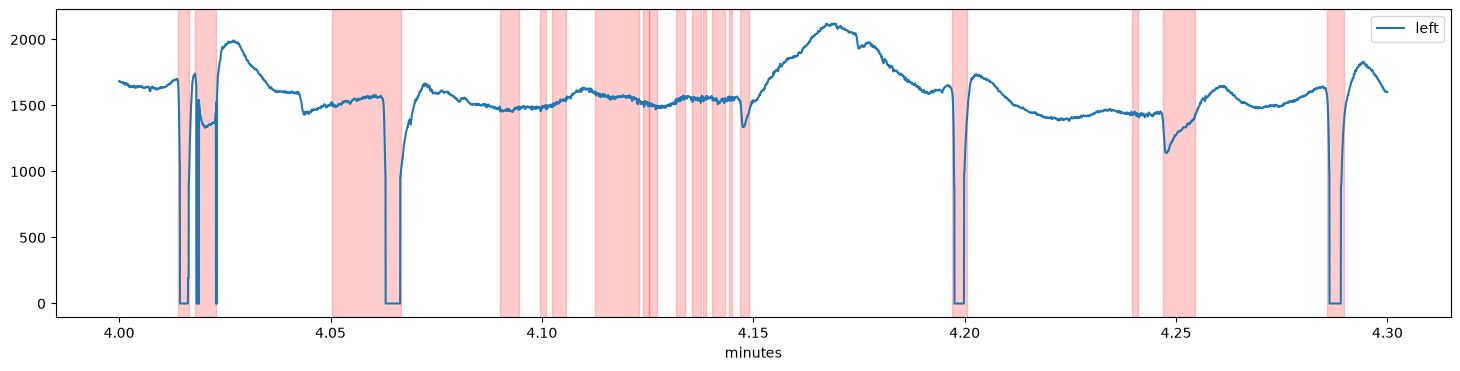

In [4]:
plt.figure(figsize=(18, 4))
d.mask_intervals(blinks, inplace=False).plot.pupil_plot(plot_range=(4, 4.3) * u.min, units="min", show_events=False)

Several periods of seemingly valid pupil data (e.g., around 4.08 and 4.17 min) were marked as blinks because of a downward change in the pupil signal which resembles the onset of a blink (a likely source of these artifacts are eye movements but we would need eyetracking data to corroborate this hypothesis).

This can be fixed by setting a stricter value for the velocity threshold `vel_onset` or by requiring a longer onset transient with `vel_onset_min_duration`:

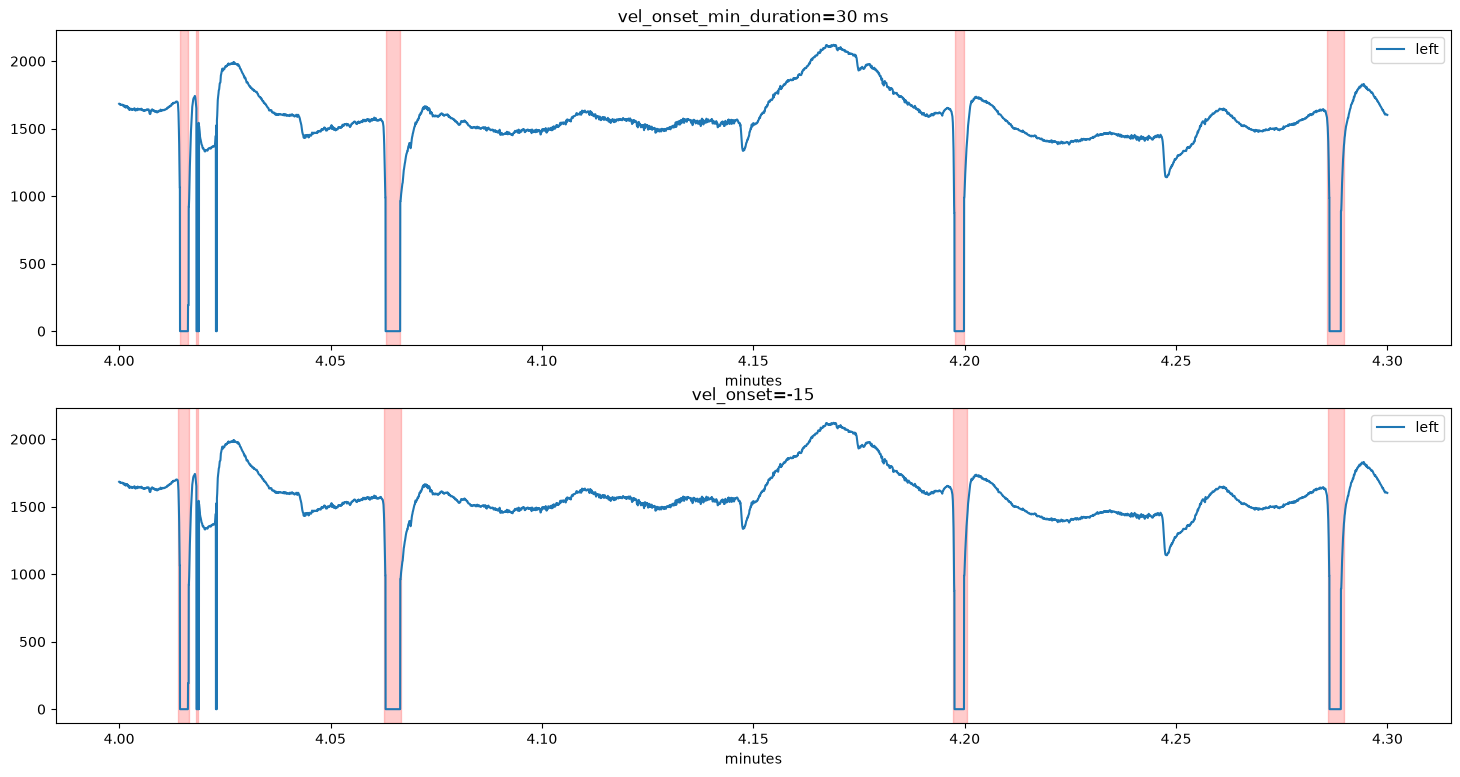

In [5]:
plt.figure(figsize=(18, 9))
d1 = d.pupil_blinks_detect(vel_onset_min_duration=30 * u.ms, apply_mask=True, inplace=False)
d2 = d.pupil_blinks_detect(vel_onset=-15, apply_mask=True, inplace=False)

plt.subplot(2, 1, 1)
d1.plot.pupil_plot(plot_range=(4, 4.3) * u.min, units="min", show_events=False)
plt.title("vel_onset_min_duration=30 ms")
plt.subplot(2, 1, 2)
d2.plot.pupil_plot(plot_range=(4, 4.3) * u.min, units="min", show_events=False)
plt.title("vel_onset=-15");

Both settings remove the false positives. However, the very short blink at 4.02 min is not detected in either case because it is shorter than the minimum blink duration (20 ms). We can decrease `min_duration`:

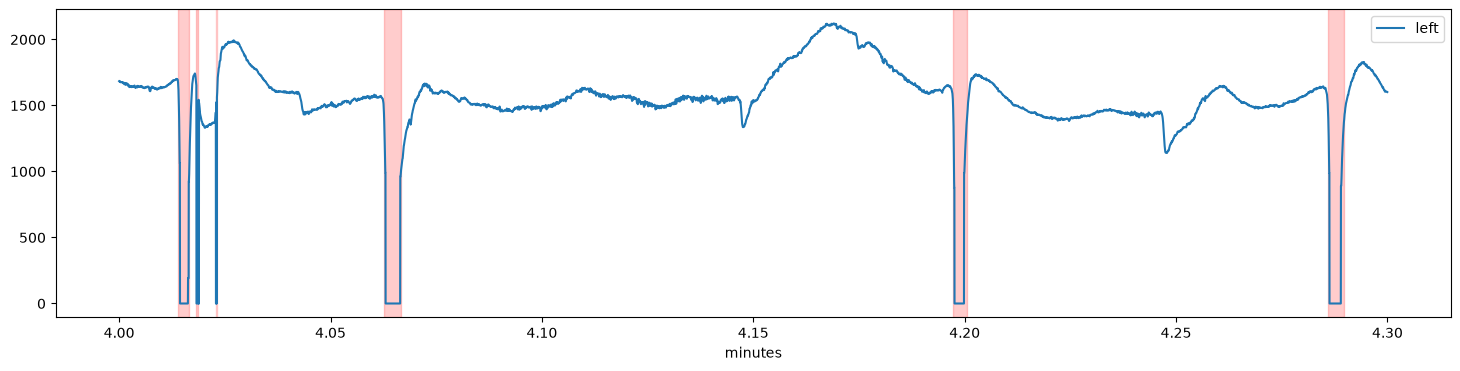

In [6]:
d.pupil_blinks_detect(vel_onset=-15, min_duration=5 * u.ms, apply_mask=True)

plt.figure(figsize=(18, 4))
d.plot.pupil_plot(plot_range=(4, 4.3) * u.min, units="min", show_events=False)

To check all detected blinks at once, `plot_blinks()` plots each blink in its own panel (it can also write the plots to a PDF file with `pdf_file=`). The number in each panel is the index of the blink, which helps to find individual blinks in the data:

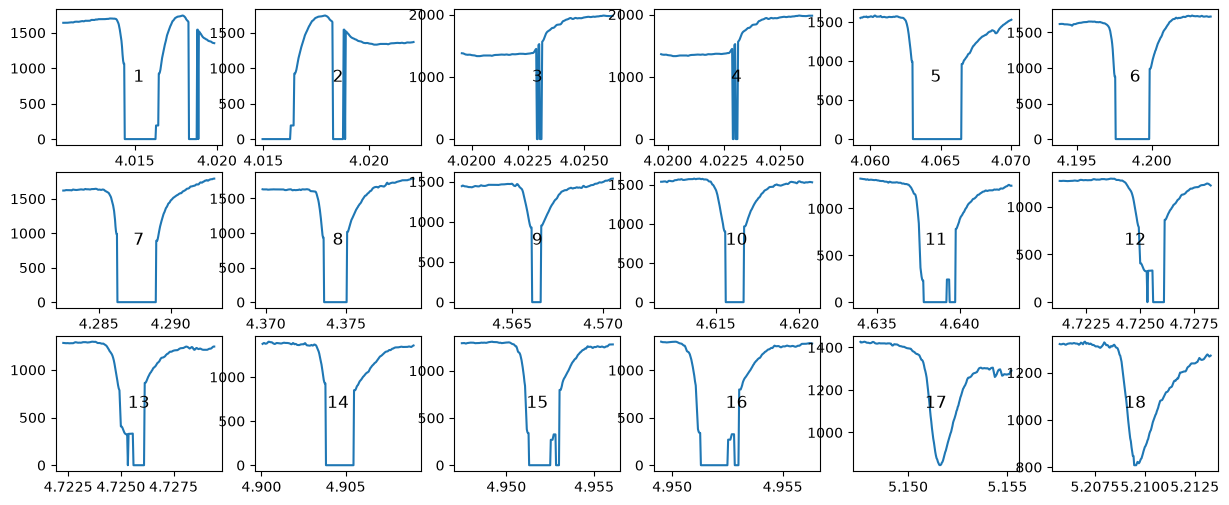

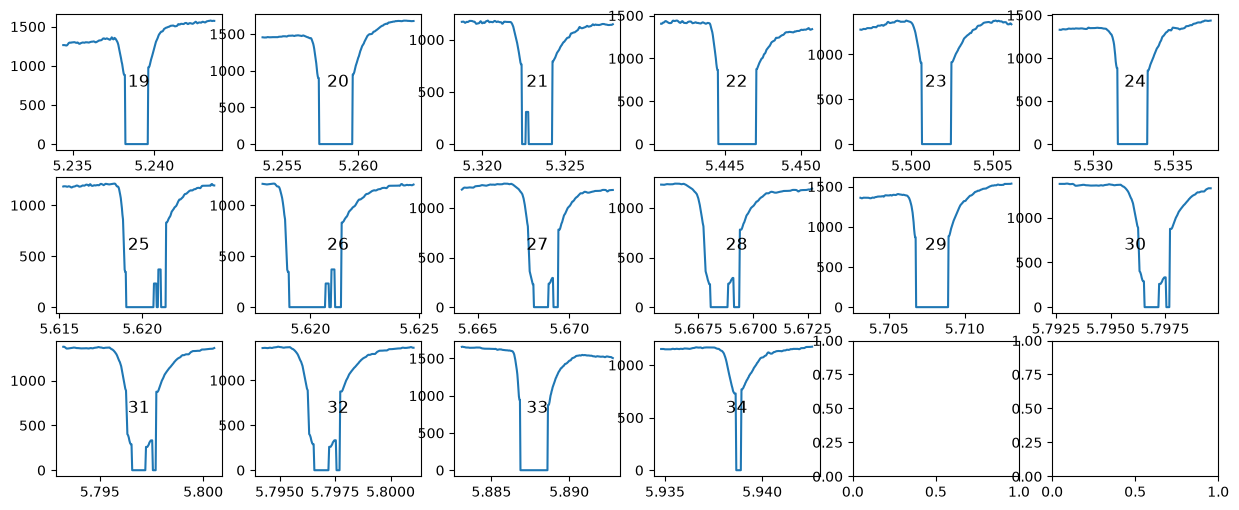

In [7]:
d.plot.plot_blinks(nrow=3, ncol=6, figsize=(15, 6));

## Merging blinks

Some subjects blink in quick succession so that the eye almost immediately starts closing again once it opens from the previous blink. In that case, it is difficult to define the onset and offset of such blink sequences and interpolation is even more difficult.

We go back to the first example above, which is from a dataset recorded in our lab. We see a couple of "normal" blinks, as well as some fast sequences of blinks (e.g., between seconds 131 and 134).

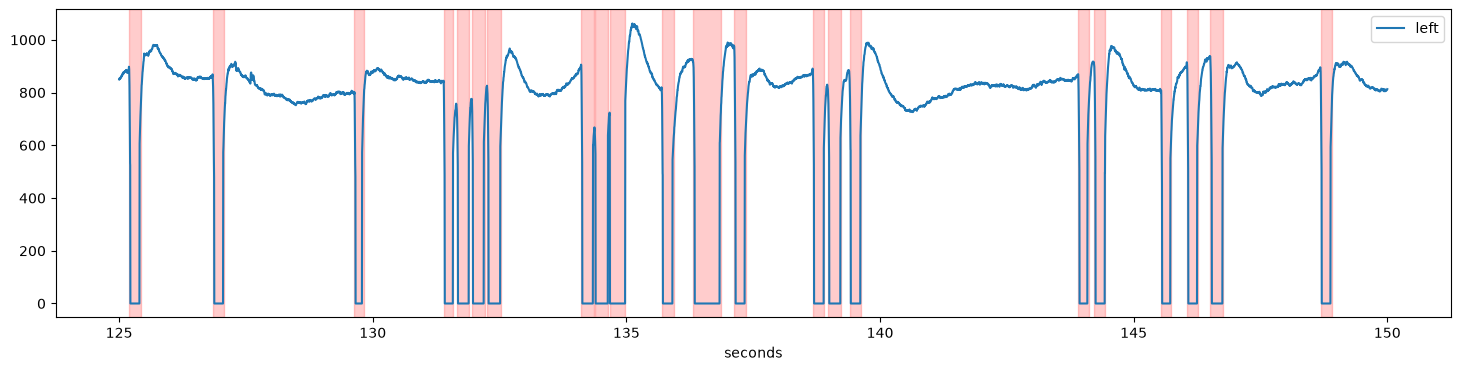

In [8]:
d = pp.PupilData.from_file("../../data/example_shortblinks.pd")
d.pupil_blinks_detect(apply_mask=True)

plt.figure(figsize=(18, 4))
d.plot.pupil_plot(show_events=False)

If we interpolated these blinks separately, the interpolation would fail because the signal "neighbouring" each blink is contaminated by other blinks. Therefore, such sequences should be merged before interpolation using `blinks_merge_close()`. The argument `distance=` sets how much clean signal there needs to be between two blinks for them to be treated as separate blinks:

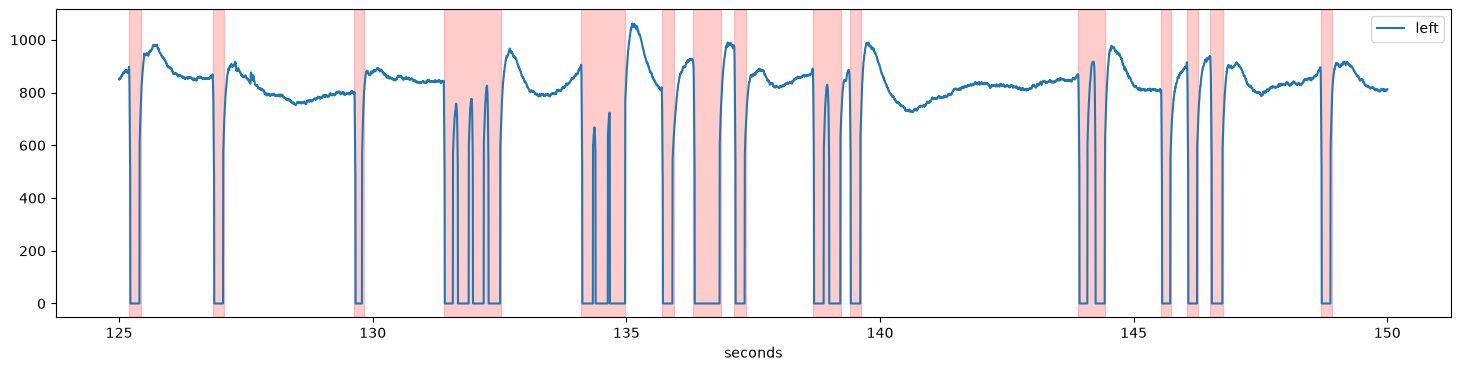

In [9]:
d.blinks_merge_close(distance=130 * u.ms, apply_mask=True)

plt.figure(figsize=(18, 4))
d.plot.pupil_plot(show_events=False)

Here, we require 130 ms of clean signal between two blinks. As a consequence, the rapid blink sequences have been merged and can be interpolated together.

## Interpolating blinks

The final step in the treatment of blinks is to replace the contaminated parts of the signal, a procedure known as *interpolation*.

`pupil_blinks_interpolate()` implements a procedure suggested by [Mahot (2013)](https://figshare.com/articles/A_simple_way_to_reconstruct_pupil_size_during_eye_blinks/688001) that uses four points around each blink for a cubic interpolation. The on- and offsets of each blink are first refined using the velocity profile, and the `margin` parameter extends the interpolated region before and after the blink.

We store the interpolated signal as a new variable (`store_as="interp"`) so that we can plot it on top of the original one:

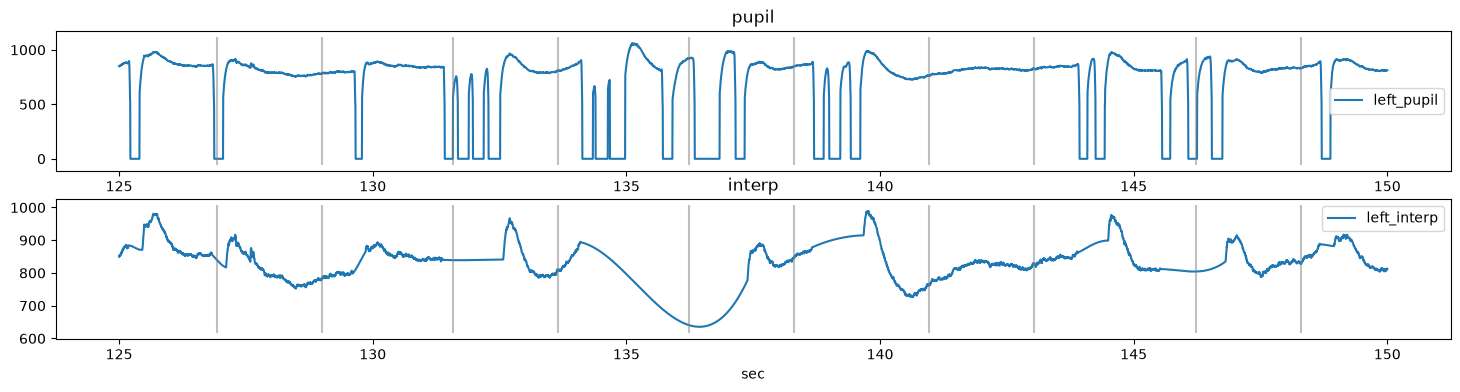

In [10]:
d.pupil_blinks_interpolate(store_as="interp")

plt.figure(figsize=(18, 4))
d.plot.plot_timeseries(variables=["pupil", "interp"], show_mask_highlight=False, units="sec")

Each blink has been replaced by a smooth curve. There are, however, some jumps in the reconstructed signal at the end of some blinks, e.g., at about 127 s and 137.5 s. The reason for this is that the opening of the eye was rather slow for this subject and therefore the signal at the end of the blinks has not yet fully recovered to the pre-blink level.

The solution for this dataset is to set the `margin` parameter to a larger value. Here, we set it to (50, 150) ms (50 ms before the onset and 150 ms after the offset). The interpolation with the larger margin has no jumps:

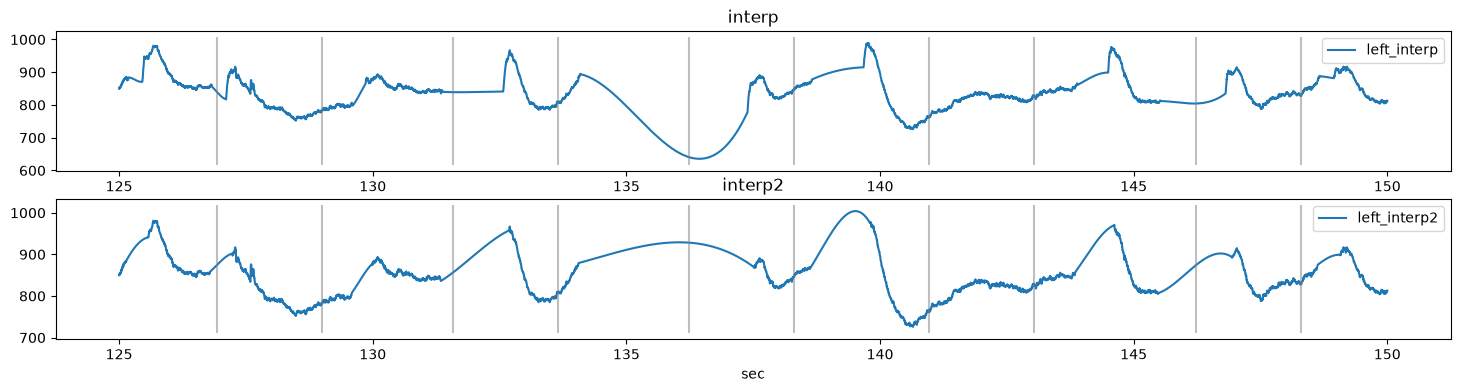

In [11]:
d.pupil_blinks_interpolate(store_as="interp2", margin=(50, 150) * u.ms)

plt.figure(figsize=(18, 4))
d.plot.plot_timeseries(variables=["interp", "interp2"], show_mask_highlight=False, units="sec")

Note that the interpolation cannot recover the signal during the long sequence of merged blinks between 134 and 137.5 s: the cubic curve only connects the signal before and after the gap. For long gaps like this one, it can be better to exclude the affected trials from the analysis.

The procedure has more parameters that can be tweaked to make the interpolation even better. Please refer to [Mahot (2013)](https://figshare.com/articles/A_simple_way_to_reconstruct_pupil_size_during_eye_blinks/688001) for a short and readable summary of what these parameters do.

Usually, you will want to replace the pupil data with the interpolated signal (`store_as="pupil"`, the default). The interpolated samples remain masked so that you can still see where data was interpolated; the interpolated blinks are also available through `get_interpolated_blinks()`. `plot_masked()` gives an overview of the masked data for all variables:

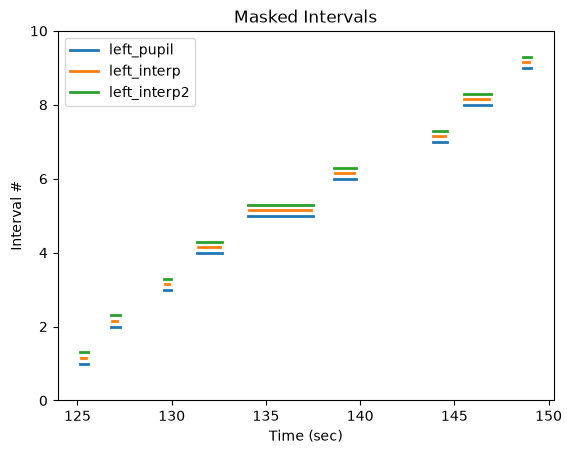

In [12]:
d.pupil_blinks_interpolate(margin=(50, 150) * u.ms)
d.plot.plot_masked(units="sec");